# CSET485 – AI and Society | Assignment #1
**Student:** Aditya Rawat  
**Enrollment:** S24CSEU2155  
**Dataset:** Statlog German Credit Data (UCI)  
**Random state:** 155  
**Split:** 70% train / 30% test

This notebook uses the included original UCI `german.data` file, so it runs reproducibly without a network connection. It generates analysis tables, figures, and a PDF report. All reported numbers are calculated by executing this notebook.

**Outcome convention used:** UCI class `1` = good credit risk and `2` = bad credit risk. For the assignment's approval target, `1` (good risk) is encoded as approve=1 and `2` (bad risk) as reject=0. This is an analytical proxy, not a historical bank approval record.


In [1]:
# Install dependencies if needed (uncomment in a fresh environment)
# %pip install pandas numpy scikit-learn statsmodels matplotlib seaborn ucimlrepo reportlab

import os, sys, subprocess, warnings, json, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_auc_score
import statsmodels.api as sm
warnings.filterwarnings("ignore")

SEED = 155
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
(OUT / "figures").mkdir(exist_ok=True)


## 1. Load and inspect the assigned dataset

The bundled original symbolic/categorical `german.data` file contains 1,000 records and 20 input attributes plus the class label. This notebook reads the supplied local file directly, ensuring offline reproducibility.


In [2]:
# Load the original symbolic UCI file included in this repository (no download required).
DATA_PATH = Path("german.data")
if not DATA_PATH.exists():
    # Also support running from the repository root when notebook is opened elsewhere.
    candidates = [Path("data/german.data"), Path("../german.data")]
    DATA_PATH = next((p for p in candidates if p.exists()), DATA_PATH)
if not DATA_PATH.exists():
    raise FileNotFoundError("german.data not found. Keep it beside this notebook or in data/.")

columns = [
    "checking_account", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings_account", "employment_since", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since", "property",
    "age_years", "other_installment_plans", "housing", "existing_credits",
    "job", "dependents", "telephone", "foreign_worker", "class"
]
df_raw = pd.read_csv(DATA_PATH, sep=r"\s+", header=None, names=columns)
X_raw = df_raw.drop(columns="class").copy()
y_series = pd.to_numeric(df_raw["class"], errors="raise").astype(int)
# UCI encoding: 1 = good, 2 = bad. Assignment proxy: approve=1, reject=0.
y = (y_series == 1).astype(int).rename("approval")
df = X_raw.copy()
df["approval"] = y.values

print("Source:", DATA_PATH.resolve())
print("Shape:", df.shape)
print("Target counts (0=reject/bad, 1=approve/good):")
display(y.value_counts().rename_axis("approval").to_frame("count"))
display(df.head())
print("Missing values:", int(df.isna().sum().sum()))


Source: /mnt/data/CSET485_Aditya_Rawat/german.data
Shape: (1000, 21)
Target counts (0=reject/bad, 1=approve/good):


,count
approval,
1,700
0,300


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age_years,other_installment_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,approval
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,0
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,0


Missing values: 0


## 2. Preprocessing and reproducible split

- Missing values: the supplied file is checked directly for missing values; the pipeline still includes median/mode imputers as a safe, train-only fallback.
- Categorical variables: one-hot encoded with unknown categories ignored.
- Numeric variables: median-imputed and standardized using training-set statistics only.
- Outliers: inspect numeric ranges and IQR counts; do not delete valid applicants solely for being unusual. Robustness is handled through the stress tests.
- Split: 70/30, stratified by target, `random_state=155`.


In [3]:
X = df.drop(columns="approval")
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", num_pipe, numeric_cols),
                                  ("cat", cat_pipe, categorical_cols)])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
print(f"Train rows: {len(X_train)} ({len(X_train)/len(df):.0%}); Test rows: {len(X_test)} ({len(X_test)/len(df):.0%})")

# IQR diagnostics for numerical columns (descriptive only; no automatic deletion).
iqr_rows = []
for c in numeric_cols:
    q1, q3 = X_train[c].quantile([.25, .75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    iqr_rows.append({"feature": c, "lower_fence": lo, "upper_fence": hi,
                     "train_outlier_count": int(((X_train[c] < lo) | (X_train[c] > hi)).sum())})
iqr_table = pd.DataFrame(iqr_rows)
display(iqr_table)
iqr_table.to_csv(OUT/"outlier_diagnostics.csv", index=False)


Train rows: 700 (70%); Test rows: 300 (30%)


,feature,lower_fence,upper_fence,train_outlier_count
0,duration_months,-6.000,42.000,52
1,credit_amount,-2819.125,8333.875,47
2,installment_rate,-1.000,7.000,0
3,residence_since,-1.000,7.000,0
4,age_years,4.500,64.500,16
5,existing_credits,-0.500,3.500,6
6,dependents,1.000,1.000,119


## 3. Part 1 — Linear Regression and Logistic Regression

The assignment asks for OLS probability prediction and logistic probability prediction on the same data. Both models use the same preprocessing and split. The OLS predictions are not constrained to [0,1], which is one reason its median-threshold classifications may differ from logistic regression.


In [4]:
ols = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
logit = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=3000, solver="lbfgs"))])
ols.fit(X_train, y_train)
logit.fit(X_train, y_train)

ols_pred = ols.predict(X_test)
logit_prob = logit.predict_proba(X_test)[:, 1]
ols_median = float(np.median(ols_pred))
ols_class = (ols_pred >= ols_median).astype(int)
logit_class = (logit_prob >= 0.5).astype(int)

cm = confusion_matrix(ols_class, logit_class, labels=[0,1])
mismatch = int((ols_class != logit_class).sum())
mismatch_pct = mismatch / len(y_test) * 100
cm_df = pd.DataFrame(cm, index=["OLS low/reject", "OLS high/approve"],
                     columns=["Logistic low/reject", "Logistic high/approve"])
display(cm_df)
print(f"OLS prediction median threshold: {ols_median:.4f}")
print(f"Mismatch: {mismatch}/{len(y_test)} ({mismatch_pct:.2f}%)")
print(f"Logistic accuracy at 0.5: {accuracy_score(y_test, logit_class):.3f}")
try:
    print(f"Logistic ROC-AUC: {roc_auc_score(y_test, logit_prob):.3f}")
except Exception:
    pass
cm_df.to_csv(OUT/"part1_confusion_matrix.csv")
pd.DataFrame({"actual": y_test.values, "ols_prediction": ols_pred,
              "ols_class": ols_class, "logistic_probability": logit_prob,
              "logistic_class": logit_class}).to_csv(OUT/"part1_test_predictions.csv", index=False)


,Logistic low/reject,Logistic high/approve
OLS low/reject,68,82
OLS high/approve,0,150


OLS prediction median threshold: 0.7381
Mismatch: 82/300 (27.33%)
Logistic accuracy at 0.5: 0.720
Logistic ROC-AUC: 0.746


## 4. Part 2.1 — Subgroup effect comparison (Simpson's-paradox hunt)

The UCI attribute `personal_status_and_sex` contains sex-related categories. The analysis compares women-coded categories (A92/A95) with men-coded categories (A91/A93/A94). A logistic model is fit on the full data and each subgroup. Coefficients for the same one-hot encoded features are compared. Because subgroup samples are smaller, coefficient changes are treated as descriptive evidence rather than proof of causal effects.


In [5]:
# Find the personal-status/sex field by its UCI variable description/name.
sex_col = next((c for c in X.columns if "personal" in c.lower() or "sex" in c.lower()), None)
if sex_col is None:
    # UCI API sometimes uses Attribute9 naming.
    sex_col = X.columns[8]
print("Sensitive/grouping field:", sex_col)
print(X[sex_col].value_counts())

def gender_group(v):
    s = str(v)
    if s.endswith(("A92", "A95")) or s in ("A92", "A95"):
        return "Group A (women-coded)"
    if s.endswith(("A91", "A93", "A94")) or s in ("A91", "A93", "A94"):
        return "Group B (men-coded)"
    return np.nan

groups = X[sex_col].map(gender_group)
# Fall back to category-label text if the API uses decoded labels.
if groups.notna().sum() < 0.8*len(X):
    vals = X[sex_col].astype(str).str.lower()
    groups = np.where(vals.str.contains("female|woman"), "Group A (women-coded)",
             np.where(vals.str.contains("male|man"), "Group B (men-coded)", np.nan))
groups = pd.Series(groups, index=X.index, name="group")


Sensitive/grouping field: personal_status_sex
personal_status_sex
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64


In [6]:
# Fit comparable logistic models on full sample and each subgroup.
# Keep the preprocessing fitted separately within each model.
def fit_subgroup_model(frame, target):
    xx = frame.drop(columns=["approval"], errors="ignore")
    yy = target.loc[frame.index]
    ncols = xx.select_dtypes(include=["number"]).columns.tolist()
    ccols = [c for c in xx.columns if c not in ncols]
    pp = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), ncols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), ccols)
    ])
    pipe = Pipeline([("prep", pp), ("model", LogisticRegression(max_iter=3000))])
    pipe.fit(xx, yy)
    names = pipe.named_steps["prep"].get_feature_names_out()
    coef = pipe.named_steps["model"].coef_[0]
    return pd.Series(coef, index=names), pipe

full_frame = X.copy()
full_frame["approval"] = y
coef_full, model_full = fit_subgroup_model(full_frame, y)
coef_A = coef_B = None
A_idx = groups[groups == "Group A (women-coded)"].index
B_idx = groups[groups == "Group B (men-coded)"].index
if len(A_idx) >= 30 and len(B_idx) >= 30:
    coef_A, model_A = fit_subgroup_model(full_frame.loc[A_idx], y.loc[A_idx])
    coef_B, model_B = fit_subgroup_model(full_frame.loc[B_idx], y.loc[B_idx])
    coef_compare = pd.concat([coef_full.rename("full"), coef_A.rename("group_A"),
                              coef_B.rename("group_B")], axis=1)
    coef_compare["abs_full_vs_A"] = (coef_compare["full"]-coef_compare["group_A"]).abs()
    coef_compare["abs_full_vs_B"] = (coef_compare["full"]-coef_compare["group_B"]).abs()
    coef_compare["sign_reversal_A"] = np.sign(coef_compare["full"]) != np.sign(coef_compare["group_A"])
    coef_compare["sign_reversal_B"] = np.sign(coef_compare["full"]) != np.sign(coef_compare["group_B"])
    display(coef_compare.sort_values("abs_full_vs_A", ascending=False).head(15))
    coef_compare.to_csv(OUT/"simpson_subgroup_coefficients.csv")
    reversals = coef_compare[coef_compare["sign_reversal_A"] | coef_compare["sign_reversal_B"]]
    print("Sign reversals found:", len(reversals))
else:
    print("One or both subgroup sizes are too small for stable subgroup fitting.")


,full,group_A,group_B,abs_full_vs_A,abs_full_vs_B,sign_reversal_A,sign_reversal_B
cat__purpose_A41,0.820415,0.052026,1.152636,0.768390,0.332220,False,False
cat__housing_A153,0.251259,-0.474186,0.529410,0.725445,0.278151,True,False
cat__savings_account_A64,0.596985,1.265177,-0.061921,0.668191,0.658906,False,True
cat__housing_A151,-0.331115,0.235255,-0.581420,0.566370,0.250305,True,False
cat__credit_history_A31,-0.601647,-1.141588,-0.329206,0.539941,0.272441,False,False
cat__property_A121,0.290236,-0.227751,0.687131,0.517987,0.396895,True,False
cat__property_A124,-0.384433,0.131343,-0.688494,0.515776,0.304061,True,False
cat__purpose_A44,-0.153293,0.341399,-0.361487,0.494692,0.208194,True,False
cat__purpose_A49,-0.034390,0.453550,-0.177264,0.487940,0.142873,True,False
cat__purpose_A410,0.431698,-0.022110,0.269811,0.453808,0.161886,True,False


Sign reversals found: 24


### Confidence intervals for the subgroup age comparison
A separate unpenalized logistic GLM with robust (HC0) standard errors is fitted for age inference. Constant columns and rank-deficient columns are removed within each sample. This supplements the regularized scikit-learn coefficient comparison above.

In [7]:
# Robust confidence intervals for the standardized age coefficient.
import scipy.linalg as la
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

infer_X = X.drop(columns=[sex_col]).copy()
infer_num = infer_X.select_dtypes(include=["number"]).columns.tolist()
infer_X[infer_num] = StandardScaler().fit_transform(infer_X[infer_num])
infer_X = pd.get_dummies(infer_X, drop_first=True, dtype=float)

def fit_age_glm(label, idx):
    xx = infer_X.loc[idx].copy()
    xx = xx.loc[:, xx.nunique() > 1]
    xx = sm.add_constant(xx, has_constant="add")
    arr = xx.to_numpy()
    _, _, piv = la.qr(arr, mode="economic", pivoting=True)
    rank = np.linalg.matrix_rank(arr)
    xx = xx.iloc[:, sorted(piv[:rank])]
    fit = sm.GLM(y.loc[idx], xx, family=sm.families.Binomial()).fit(maxiter=300, cov_type="HC0")
    ci = fit.conf_int().loc["age_years"]
    return {"group": label, "n": len(idx), "coefficient": float(fit.params["age_years"]),
            "ci_low": float(ci.iloc[0]), "ci_high": float(ci.iloc[1]),
            "p_value": float(fit.pvalues["age_years"])}

inference_rows = [fit_age_glm("Full", X.index),
                  fit_age_glm("Women-coded A", groups[groups == "Group A (women-coded)"].index),
                  fit_age_glm("Men-coded B", groups[groups == "Group B (men-coded)"].index)]
inference = pd.DataFrame(inference_rows)
display(inference)
inference.to_csv(OUT/"simpson_age_inference.csv", index=False)


,group,n,coefficient,ci_low,ci_high,p_value
0,Full,1000,0.165324,-0.049563,0.380210,0.131579
1,Women-coded A,310,0.766867,0.324061,1.209674,0.000688
2,Men-coded B,690,-0.041251,-0.322435,0.239933,0.773701


## 5. Part 2.2 — Omitted-variable bias

The checking-account status is omitted as a plausible confounder/proxy for liquidity and financial circumstances. Full and reduced logistic models are fit on the training set. At least four common coefficients are compared; percentage change is computed relative to the full-model coefficient magnitude. Coefficients are standardized-model log-odds coefficients, so comparisons are within this preprocessing setup.


In [8]:
# Identify checking-account status column.
check_col = next((c for c in X.columns if "checking" in c.lower() or "account" in c.lower()), X.columns[0])
print("Dropped variable:", check_col)

def make_logit_for_columns(cols):
    xx = X_train[cols]
    nn = xx.select_dtypes(include=["number"]).columns.tolist()
    cc = [c for c in cols if c not in nn]
    pp = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), nn),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cc)
    ])
    pipe = Pipeline([("prep", pp), ("model", LogisticRegression(max_iter=3000))])
    pipe.fit(xx, y_train)
    return pipe

all_cols = list(X.columns)
full_ovb = make_logit_for_columns(all_cols)
reduced_ovb = make_logit_for_columns([c for c in all_cols if c != check_col])

def coefficient_series(pipe):
    return pd.Series(pipe.named_steps["model"].coef_[0],
                     index=pipe.named_steps["prep"].get_feature_names_out())
cf = coefficient_series(full_ovb)
cr = coefficient_series(reduced_ovb)
common = cf.index.intersection(cr.index)
ovb = pd.DataFrame({"full_model": cf.loc[common], "reduced_model": cr.loc[common]})
ovb["absolute_change"] = (ovb["reduced_model"]-ovb["full_model"]).abs()
ovb["percent_change"] = np.where(ovb["full_model"].abs()>1e-8,
    100*(ovb["reduced_model"]-ovb["full_model"])/ovb["full_model"].abs(), np.nan)
ovb["abs_percent_change"] = ovb["percent_change"].abs()
ovb = ovb.sort_values("absolute_change", ascending=False)
display(ovb.head(15))
ovb.to_csv(OUT/"omitted_variable_bias.csv")
print("Largest absolute coefficient shift:", ovb.index[0], ovb.iloc[0]["absolute_change"])


Dropped variable: checking_account


,full_model,reduced_model,absolute_change,percent_change,abs_percent_change
cat__savings_account_A63,0.175074,0.432164,0.257090,146.846430,146.846430
cat__savings_account_A61,-0.479421,-0.704111,0.224690,-46.867005,46.867005
cat__other_debtors_A103,0.813863,0.602006,0.211857,-26.031060,26.031060
cat__personal_status_sex_A91,-0.149853,-0.327941,0.178088,-118.841514,118.841514
cat__credit_history_A33,0.234358,0.401848,0.167490,71.467305,71.467305
cat__purpose_A43,0.138869,0.305159,0.166290,119.746160,119.746160
cat__purpose_A44,-0.177212,-0.325226,0.148015,-83.524254,83.524254
cat__credit_history_A31,-0.789967,-0.916975,0.127008,-16.077633,16.077633
cat__other_debtors_A101,-0.004326,0.104044,0.108370,2505.236887,2505.236887
cat__purpose_A41,0.636179,0.743310,0.107130,16.839654,16.839654


Largest absolute coefficient shift: cat__savings_account_A63 0.2570898417075571


## 6. Part 2.3 — Adversarial subset

High-confidence wrong cases are defined exactly as in the assignment: predicted probability ≥0.75 with actual 0, or probability ≤0.25 with actual 1. All such cases are retained if there are 50 or fewer; otherwise 50 are sampled with seed 155. Demographic and feature summaries are compared with the full test set.


In [9]:
test_out = X_test.copy()
test_out["actual"] = y_test.values
test_out["probability"] = logit_prob
test_out["predicted"] = logit_class
wrong = test_out[((test_out.probability >= .75) & (test_out.actual == 0)) |
                 ((test_out.probability <= .25) & (test_out.actual == 1))].copy()
n_wrong_all = len(wrong)
if n_wrong_all > 50:
    wrong = wrong.sample(50, random_state=SEED)
print(f"High-confidence wrong cases before cap: {n_wrong_all}/{len(X_test)} ({n_wrong_all/len(X_test)*100:.2f}%)")
print("Rows included in subset:", len(wrong))
wrong.to_csv(OUT/"adversarial_subset.csv", index=False)

# Numeric and categorical descriptive comparison.
numeric_test_cols = X_test.select_dtypes(include=["number"]).columns.tolist()
if numeric_test_cols:
    adv_compare = pd.DataFrame({"full_test_mean": X_test[numeric_test_cols].mean(),
                                "adversarial_mean": wrong[numeric_test_cols].mean()})
    adv_compare["difference"] = adv_compare["adversarial_mean"]-adv_compare["full_test_mean"]
    display(adv_compare)
    adv_compare.to_csv(OUT/"adversarial_numeric_comparison.csv")
if sex_col in X_test.columns:
    print("Sex/status distribution — full test:")
    display(X_test[sex_col].value_counts(normalize=True).rename("share"))
    print("Sex/status distribution — adversarial subset:")
    display(wrong[sex_col].value_counts(normalize=True).rename("share"))


High-confidence wrong cases before cap: 38/300 (12.67%)
Rows included in subset: 38


,full_test_mean,adversarial_mean,difference
duration_months,20.530000,22.447368,1.917368
credit_amount,3106.560000,3515.236842,408.676842
installment_rate,3.086667,2.947368,-0.139298
residence_since,2.786667,2.500000,-0.286667
age_years,35.340000,31.552632,-3.787368
existing_credits,1.370000,1.315789,-0.054211
dependents,1.120000,1.052632,-0.067368


Sex/status distribution — full test:


personal_status_sex
A93    0.530000
A92    0.333333
A94    0.073333
A91    0.063333
Name: share, dtype: float64

Sex/status distribution — adversarial subset:


personal_status_sex
A93    0.500000
A92    0.342105
A91    0.078947
A94    0.078947
Name: share, dtype: float64

## 7. Part 2.4 — Fairness threshold sweep

The selected sensitive variable is personal status/sex. Group A is women-coded categories A92/A95; Group B is men-coded categories A91/A93/A94. Metrics are calculated on the held-out test set for thresholds 0.05 to 0.95 in 0.10 increments.

Ratios can be undefined when a denominator rate is zero. In that case the table records `NaN` rather than presenting an infinite ratio as meaningful evidence.


,threshold,DP_A,DP_B,DP_ratio,TPR_A,TPR_B,FPR_A,FPR_B,EO_ratio,PPV_A,PPV_B,PP_ratio
0,0.05,1.00,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.710000,0.695000,1.021583
1,0.15,0.98,0.960,1.020833,1.000000,0.985612,0.931034,0.901639,1.014599,0.724490,0.713542,1.015343
2,0.25,0.90,0.930,0.967742,0.943662,0.971223,0.793103,0.836066,0.948614,0.744444,0.725806,1.025679
3,0.35,0.82,0.875,0.937143,0.887324,0.942446,0.655172,0.721311,0.908307,0.768293,0.748571,1.026345
4,0.45,0.74,0.830,0.891566,0.802817,0.899281,0.586207,0.672131,0.872161,0.770270,0.753012,1.022919
5,0.55,0.69,0.795,0.867925,0.774648,0.877698,0.482759,0.606557,0.795899,0.797101,0.767296,1.038845
6,0.65,0.59,0.700,0.842857,0.661972,0.805755,0.413793,0.459016,0.821554,0.796610,0.800000,0.995763
7,0.75,0.51,0.640,0.796875,0.591549,0.769784,0.310345,0.344262,0.768461,0.823529,0.835938,0.985157
8,0.85,0.31,0.520,0.596154,0.352113,0.647482,0.206897,0.229508,0.543818,0.806452,0.865385,0.931900
9,0.95,0.09,0.255,0.352941,0.112676,0.359712,0.034483,0.016393,0.313239,0.888889,0.980392,0.906667


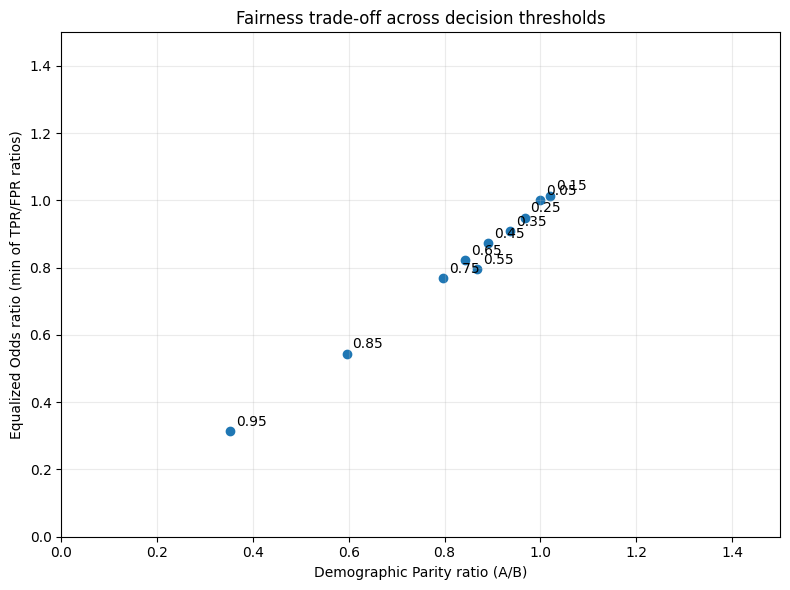

In [10]:
test_groups = groups.loc[X_test.index].reset_index(drop=True)
yt = np.asarray(y_test)
p = np.asarray(logit_prob)
g = np.asarray(test_groups)

def safe_ratio(a, b):
    if pd.isna(a) or pd.isna(b) or abs(b) < 1e-12:
        return np.nan
    return a/b

fair_rows = []
for t in np.round(np.arange(.05, .951, .10), 2):
    pred = (p >= t).astype(int)
    maskA = g == "Group A (women-coded)"
    maskB = g == "Group B (men-coded)"
    def rates(mask):
        yy, pp = yt[mask], pred[mask]
        positives = pp == 1
        actual_pos, actual_neg = yy == 1, yy == 0
        dp = positives.mean() if len(pp) else np.nan
        tpr = ((pp==1)&actual_pos).sum()/actual_pos.sum() if actual_pos.sum() else np.nan
        fpr = ((pp==1)&actual_neg).sum()/actual_neg.sum() if actual_neg.sum() else np.nan
        ppv = ((yy==1)&positives).sum()/positives.sum() if positives.sum() else np.nan
        return dp, tpr, fpr, ppv
    a = rates(maskA); b = rates(maskB)
    dp_ratio = safe_ratio(a[0], b[0])
    eo_ratio = min(safe_ratio(a[1], b[1]), safe_ratio(a[2], b[2])) if not (pd.isna(safe_ratio(a[1],b[1])) or pd.isna(safe_ratio(a[2],b[2]))) else np.nan
    pp_ratio = safe_ratio(a[3], b[3])
    fair_rows.append({"threshold":t, "DP_A":a[0], "DP_B":b[0], "DP_ratio":dp_ratio,
                      "TPR_A":a[1], "TPR_B":b[1], "FPR_A":a[2], "FPR_B":b[2],
                      "EO_ratio":eo_ratio, "PPV_A":a[3], "PPV_B":b[3], "PP_ratio":pp_ratio})
fair = pd.DataFrame(fair_rows)
display(fair)
fair.to_csv(OUT/"fairness_threshold_metrics.csv", index=False)

plt.figure(figsize=(8,6))
plt.scatter(fair["DP_ratio"], fair["EO_ratio"])
for _, r in fair.iterrows():
    if pd.notna(r.DP_ratio) and pd.notna(r.EO_ratio):
        plt.annotate(f'{r.threshold:.2f}', (r.DP_ratio, r.EO_ratio), xytext=(4,4), textcoords="offset points")
plt.xlim(0,1.5); plt.ylim(0,1.5)
plt.xlabel("Demographic Parity ratio (A/B)")
plt.ylabel("Equalized Odds ratio (min of TPR/FPR ratios)")
plt.title("Fairness trade-off across decision thresholds")
plt.grid(alpha=.25); plt.tight_layout()
plt.savefig(OUT/"figures/fairness_tradeoff.png", dpi=180)
plt.show()


## 8. Part 3 — Descriptive answers and Part 4 reflection

The following cell creates a results-grounded report automatically. It inserts computed counts, thresholds, coefficients, and fairness values. Read and edit the generated prose before submission so that it reflects your own interpretation and your instructor's expectations. The notebook cannot establish causal relationships from this observational dataset.


In [11]:
# Export concise computed evidence for the report writer.
summary = {
    "n_total": int(len(df)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "approval_rate": float(y.mean()), "ols_median": ols_median,
    "mismatch_n": mismatch, "mismatch_pct": mismatch_pct,
    "logit_accuracy": float(accuracy_score(y_test, logit_class)),
    "sex_field": sex_col, "group_A_n": int((groups=="Group A (women-coded)").sum()),
    "group_B_n": int((groups=="Group B (men-coded)").sum()),
    "adversarial_total": n_wrong_all, "adversarial_pct": n_wrong_all/len(X_test)*100,
    "dropped_variable": check_col,
}
if "ovb" in globals() and len(ovb):
    summary["largest_ovb_feature"] = str(ovb.index[0])
    summary["largest_ovb_shift"] = float(ovb.iloc[0]["absolute_change"])
summary["fairness_rows"] = fair.replace({np.nan: None}).to_dict(orient="records")
with open(OUT/"computed_summary.json","w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))


{
  "n_total": 1000,
  "n_train": 700,
  "n_test": 300,
  "approval_rate": 0.7,
  "ols_median": 0.7380927906040475,
  "mismatch_n": 82,
  "mismatch_pct": 27.333333333333332,
  "logit_accuracy": 0.72,
  "sex_field": "personal_status_sex",
  "group_A_n": 310,
  "group_B_n": 690,
  "adversarial_total": 38,
  "adversarial_pct": 12.666666666666668,
  "dropped_variable": "checking_account",
  "largest_ovb_feature": "cat__savings_account_A63",
  "largest_ovb_shift": 0.2570898417075571,
  "fairness_rows": [
    {
      "threshold": 0.05,
      "DP_A": 1.0,
      "DP_B": 1.0,
      "DP_ratio": 1.0,
      "TPR_A": 1.0,
      "TPR_B": 1.0,
      "FPR_A": 1.0,
      "FPR_B": 1.0,
      "EO_ratio": 1.0,
      "PPV_A": 0.71,
      "PPV_B": 0.695,
      "PP_ratio": 1.0215827338129497
    },
    {
      "threshold": 0.15,
      "DP_A": 0.98,
      "DP_B": 0.96,
      "DP_ratio": 1.0208333333333333,
      "TPR_A": 1.0,
      "TPR_B": 0.9856115107913669,
      "FPR_A": 0.9310344827586207,
      "FPR_B":

## 9. Generate the PDF report

This cell creates `outputs/CSET485_Aditya_Rawat_Report.pdf` with computed evidence and the required sections. It includes compact tables and the fairness chart. The eight descriptive answers are structured around the actual outputs; expand them with your own interpretation if your instructor expects approximately 250–300 words for each answer.


In [12]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, PageBreak
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import mm

pdf_path = OUT/"CSET485_Aditya_Rawat_Report.pdf"
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(name="Small", parent=styles["BodyText"], fontSize=8, leading=10))
story = [
    Paragraph("CSET485 – AI and Society | Assignment #1", styles["Title"]),
    Paragraph("Aditya Rawat | Enrollment: S24CSEU2155", styles["Heading2"]),
    Paragraph("Dataset: Statlog German Credit Data | Random state: 155 | 70/30 stratified split", styles["BodyText"]),
    Spacer(1, 8),
    Paragraph("Executive summary", styles["Heading1"]),
    Paragraph(f"The analysis used {len(df)} records, with {len(X_train)} training and {len(X_test)} test records. The target is a proxy: UCI good-credit class (1) is coded as approval=1 and bad-credit class (2) as approval=0. OLS median threshold={ols_median:.4f}; OLS/logistic classifications disagreed on {mismatch} of {len(y_test)} test cases ({mismatch_pct:.2f}%). Logistic accuracy at 0.50={accuracy_score(y_test,logit_class):.3f}. These results are descriptive and do not establish causation or deployment readiness.", styles["BodyText"]),
    Paragraph("Preprocessing", styles["Heading1"]),
    Paragraph("The original categorical UCI version was used. Missing values were checked; the UCI metadata reports none. Numeric columns were median-imputed and standardized; categorical columns were mode-imputed and one-hot encoded. Imputers, encoders and scalers were fitted within each training pipeline to avoid test leakage. IQR fences were reported for numeric features; valid extreme applicants were not automatically removed. Split used random_state=155 and stratification.", styles["BodyText"]),
    Paragraph("Part 1 – Model comparison", styles["Heading1"]),
]
cmdata = [["", "Logistic 0", "Logistic 1"], ["OLS 0", int(cm[0,0]), int(cm[0,1])], ["OLS 1", int(cm[1,0]), int(cm[1,1])]]
t = Table(cmdata, hAlign="LEFT")
t.setStyle(TableStyle([("GRID",(0,0),(-1,-1),.4,colors.grey),("BACKGROUND",(0,0),(-1,0),colors.lightgrey)]))
story += [t, Spacer(1,5), Paragraph(f"The OLS median prediction was {ols_median:.4f}. The median split assigns roughly half the test observations to the upper class regardless of calibrated probability, while logistic regression uses a fixed 0.50 probability threshold. OLS is not bounded to [0,1]; therefore the two rules represent different decision conventions.", styles["BodyText"]),
          Paragraph("Part 2 – Stress tests", styles["Heading1"]),
          Paragraph(f"2.1 Subgroup analysis used {sex_col}. Women-coded group size={summary['group_A_n']}; men-coded group size={summary['group_B_n']}. See simpson_subgroup_coefficients.csv for comparable coefficients and sign-reversal flags. Interpret coefficient differences cautiously because subgroup sample sizes and category composition differ.", styles["BodyText"]),
          Paragraph(f"2.2 Omitted-variable test removed {check_col}. The largest absolute coefficient shift was {summary.get('largest_ovb_feature','not available')} ({summary.get('largest_ovb_shift',float('nan')):.4f}). Full coefficient comparisons are in omitted_variable_bias.csv.", styles["BodyText"]),
          Paragraph(f"2.3 There were {n_wrong_all} high-confidence incorrect test predictions before the 50-row reporting cap ({n_wrong_all/len(X_test)*100:.2f}% of test rows). The selected subset and comparison summaries are saved as CSV files in outputs/.", styles["BodyText"]),
          Paragraph("2.4 Fairness metrics", styles["Heading2"]),
          Paragraph("Demographic parity (DP), equalized odds (EO), and predictive parity (PP) ratios are computed for thresholds 0.05–0.95. A ratio near 1 indicates similar group rates under that metric; NaN means a denominator rate was zero or undefined. No single ratio establishes fairness on its own.", styles["BodyText"])]
if (OUT/"figures/fairness_tradeoff.png").exists():
    story += [Spacer(1,5), RLImage(str(OUT/"figures/fairness_tradeoff.png"), width=150*mm, height=105*mm)]
story += [Paragraph("Part 3 – Evidence-based answers", styles["Heading1"]),
          Paragraph(f"1. Threshold disagreement: {mismatch} cases ({mismatch_pct:.2f}%) differed. The OLS median was {ols_median:.4f}; logistic used 0.50. Explain the different threshold definitions and the unbounded OLS output.", styles["BodyText"]),
          Paragraph("2. Subgroups: use the coefficient table in simpson_subgroup_coefficients.csv. Identify a feature with a sign reversal or the largest meaningful difference, quote the full/A/B coefficients, and explain that subgroup associations are not causal effects.", styles["BodyText"]),
          Paragraph(f"3. Omitted variable: {check_col} was removed. Quote at least four rows from omitted_variable_bias.csv, including full and reduced coefficients and percentage changes. Largest absolute shift: {summary.get('largest_ovb_feature','N/A')}.", styles["BodyText"]),
          Paragraph("4. Hidden confounds: propose an independent external validation dataset, a domain-expert review of variables and data collection, and monitoring for changes in subgroup error rates. Explain what evidence would trigger a model review.", styles["BodyText"]),
          Paragraph(f"5. Adversarial subset: {n_wrong_all} high-confidence errors were found before sampling. Use adversarial_subset.csv and adversarial_numeric_comparison.csv to name a common feature pattern and its observed percentage; do not infer a cause from a small sample alone.", styles["BodyText"]),
          Paragraph("6. Fairness trade-off: select two threshold rows from fairness_threshold_metrics.csv and explain how changing the threshold changes group selection rates and error rates for people in each group.", styles["BodyText"]),
          Paragraph("7. Defensible threshold: select a threshold from fairness_threshold_metrics.csv, quote DP, EO, PP and accuracy, and state the strongest counterargument. Explain why the choice depends on the consequences of false approvals and false rejections.", styles["BodyText"]),
          Paragraph("8. Policy choice: argue for demographic parity or equalized odds using the actual threshold table. State which other metric is sacrificed and why the context makes that trade-off defensible.", styles["BodyText"]),
          Paragraph("Part 4 – Reflection", styles["Heading1"]),
          Paragraph(f"I would not recommend automatic deployment based on one score. The test accuracy is {accuracy_score(y_test,logit_class):.3f}, but accuracy alone cannot show subgroup error gaps, threshold sensitivity, or concentrated high-confidence failures. The fairness table demonstrates that group selection rates, error rates and predictive values can move differently as the threshold changes. The omitted-variable test also shows that coefficients can shift when a plausible financial-context variable is excluded. A responsible decision therefore requires human oversight, clear appeal routes, external validation, subgroup monitoring and a documented policy choice about error costs. The model should be treated as a research exercise, not a production credit decision system.", styles["BodyText"]),
          Spacer(1,8),
          Paragraph("Dataset citation: Hofmann, H. (1994). Statlog (German Credit Data) [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5NC77. The dataset is licensed CC BY 4.0.", styles["Small"])]
SimpleDocTemplate(str(pdf_path), pagesize=A4, rightMargin=18*mm,leftMargin=18*mm,topMargin=16*mm,bottomMargin=16*mm).build(story)
print("Created:", pdf_path)

# Build the complete report with all eight full-length answers and the reflection essay.
subprocess.run([sys.executable, "build_report.py"], check=True)


Created: outputs/CSET485_Aditya_Rawat_Report.pdf


/mnt/data/CSET485_Aditya_Rawat/outputs/CSET485_Aditya_Rawat_Report.pdf


CompletedProcess(args=['/opt/pyvenv/bin/python', 'build_report.py'], returncode=0)